# Array configuration notebook

### Instructions before running the notebook

In order to run this document, you will need to have argosim installed. This can be done using:

pip install argosim

Alternatively, you can follow the instructions in the argosim github repository: https://github.com/ARGOS-telescope/argosim

In [24]:
import os
import glob

import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.widgets import TextBox
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import numpy as np

import astropy.units as u
from astropy.table import QTable
import astropy.constants as constants
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, Galactic
from astropy.time import Time
from astropy.modeling import models, fitting
from astropy.io import fits

import healpy as hp

import scipy
import scipy.special
from scipy.ndimage import map_coordinates
from scipy.signal import find_peaks

import argosim
from argosim import antenna_utils, plot_utils, beam_utils, imaging_utils
from argosim.clean import *

from itertools import combinations

from PIL import Image

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

from argosim import antenna_utils as aat
from argosim import data_utils  as adu
from argosim import plot_utils  as apu
from argosim import optim_utils as aou

## Setup ARGOSIM

In [11]:
#Constants
frequency = 1.42e9*u.hertz 
samp_rate = 1e7*(1/u.second)
bins = 1024
num_chan = int(32e3)

diam_ant = 0.18

n_antenna = 9
n_antenna_E = 3
n_antenna_N = 3

radius_antenna_grid = 2

lat = 52.16 / 180 * np.pi
lat_deg = 52.16
dec = 35.0 / 180 * np.pi
dec_deg = 35.0

npix = 256

In [12]:
# Definitions, functions, classes

def uv_tracks(baselines, track_time=1/3, t_0=0, n_times=5, f=frequency, df=10e6, n_freqs=num_chan, lat=lat_deg,dec=lat_deg):
    """ Calculate the uv tracks made by an array configuration.
    Default values from single cantenna experiment.
    
    baselines :     baselines for the array configuration (list)
    track_time :    observation duration in hours (float)
    t_0 :           start time in hours ()
    n_times :       how many observations (int)
    f :             frequency of observation (Hz)
    df :            frequency range (Hz) 
    n_frequs :      number of frequency samples (number of channels) (int)
    lat :           latitude (deg), default Leiden (NL)
    """

    lat = lat * np.pi / 180 # in radians
    dec = lat # assuming it's at the zenith  # TODO
    
    uv_track, _ = antenna_utils.uv_track_multiband(baselines, lat=lat, dec=dec, track_time=track_time, t_0=t_0, 
                                                    n_times=n_times, f=f, df=df, n_freqs=int(n_freqs), multi_band=False)

    uv_array = uv_track
    return uv_array


def laptop_dist(ant_array, laptop_pos, max_dist=10.):
    """ Calculate distance between array points and one laptop. (curvy gound not taken into account bc meh) 

    ant_array  : positions of antennas [x,y,z]
    laptop_pos : position of laptop [x,y,z]
    max_dist   : maximum allowed distance between laptop and antenna (meters) (float)
    makefig    : make figure of the situation (plot_laptop_dist function)
    """ 
    distances, too_far = [], []
    for i in range(len(ant_array)):
        x_ant, y_ant, z_ant = ant_array[i,0], ant_array[i,1], ant_array[i,2]
        distance = np.sqrt(np.abs(x_ant-laptop_pos[0])**2 + np.abs(y_ant-laptop_pos[1])**2 + np.abs(z_ant-laptop_pos[2])**2)
        if distance >= max_dist:
            print(f'Max allowed distance exceeded: {np.round(distance, 3)} m between laptop and antenna at {ant_array[i]}.') 
            too_far.append(i)
        distances.append(distance)
        
    return distances, too_far

    
def plot_config(positions, color=None, title='Antenna array', savefig=False):
    """ plot antenna configuration in x,y plane
    positions: list of [x,y,z]
    """ 
    fig, axs = plt.subplots(1,1, figsize=(5,5))
    axs.plot(positions[:,0], positions[:,1], '.', color=color)
    axs.set_title(title)
    axs.set_xlabel('x (East) [m]') 
    axs.set_ylabel('y (North) [m]')
    axs.grid()
    if savefig:
        plt.savefig('./figures/antenna_array.pdf')
    plt.show()
    return


def plot_uv(uv_track, color=None, title='uv tracks', savefig=False):
    """ plot uv coverage
    uv_track : as calculated by uv_tracks
    """
    fig, axs = plt.subplots(1,1, figsize=(5,5))
    axs.plot(uv_track[:,0], uv_track[:,1], '.', color=color)
    axs.set_xlabel('u')
    axs.set_ylabel('v')
    axs.set_title(title)
    axs.grid(alpha=.5)
    if savefig:
        plt.savefig('./figures/uv-tracks.pdf')
    plt.show()
    return


def plot_laptop_dist(ant_array, laptop_pos, max_dist, distances=None, suppress_gray=False, offset=0., savefig=False):
    """ Plot the array situation and laptop position. If distances is not given, it will be calculated here.
    
    ant_array :  array with antenna positions [x,y,z]
    laptop_pos : laptop position [x,y,z]
    max_dist :   max distance between laptop and antenna
    distances :  calculated distances between antenna and laptop

    Plot options:
    suppress_gray : suppress gray lines
    offset :        offset for the distance labels in the plot
    savefig :       save figure
    """
    if distances==None:
        distances, too_far = laptop_dist(ant_array, laptop_pos, max_dist)
        
    fig, axs = plt.subplots(1,1, figsize=(6,6))
    
    # Draw lines between laptop and antennas
    for i in range(len(ant_array)):
        if i in too_far:
            axs.plot([ant_array[:,0][i],laptop_pos[0]], [ant_array[:,1][i],laptop_pos[1]], alpha=.4, color='red')
            axs.annotate(f'{np.round(distances[i],2)} m', xy=(ant_array[:,0][i]+offset, ant_array[:,1][i]+offset), size=10, color='maroon')
        else:
            if suppress_gray:
                pass
            else:
                axs.plot([ant_array[:,0][i],laptop_pos[0]], [ant_array[:,1][i],laptop_pos[1]], alpha=.4, color='gray')
                axs.annotate(f'{np.round(distances[i],2)} m', xy=(ant_array[:,0][i]+offset, ant_array[:,1][i]+offset), size=10)
        
    # Draw laptop and antenna points
    axs.plot(ant_array[:,0], ant_array[:,1], '.', color='black', markersize=8, label='antennas')
    axs.plot(laptop_pos[0], laptop_pos[1], color='fuchsia', marker='*', markersize=8, label='laptop')
        
    axs.set_title('Antenna configuration with laptop')
    axs.set_xlabel('x (East) [m]') 
    axs.set_ylabel('y (North) [m]')
    axs.grid(alpha=.5)
    axs.legend(handles=[Line2D([0],[0], marker='o', linewidth=0, markersize=8, color='black', label='antenna'),
                 Line2D([0],[0], marker='*', linewidth=0, markersize=8, color='fuchsia', label='laptop')])

    if savefig:
        plt.savefig('./figures/antenna_laptop_config.pdf')
    plt.show()

    return

    
def compute_max_baseline(array):
    """
    compute the maximum baseline from the array.
    """
    separations = np.array([array[i]-array[j] for i in range(len(array)) for j in range(len(array))])
    separations = np.linalg.norm(separations, axis=1)
    max_separation = np.max(separations)
    max_separation_indices = np.unravel_index(np.argmax(separations), (len(array), len(array)))
    # add one to match antenna indices starting from 1
    max_separation_indices = (max_separation_indices[0] + 1, max_separation_indices[1] + 1)

    return max_separation, max_separation_indices



#Airy beam instead of standard argosim CosCube
def airy_beam_fn(first_null_radius):
    """
    Returns the Airy power pattern of a circular aperture.

    Parameters
    ----------
    first_null_radius : astropy.units.Quantity
        Angular radius from the beam centre to its first null.
    """

    def fn(angular_distance):

        x = (
            3.83170597
            * angular_distance.to(u.rad)
            / first_null_radius.to(u.rad)
        ).value

        result = np.ones_like(x, dtype=float)
        mask = np.abs(x) > 1e-10

        result[mask] = (
            2 * scipy.special.j1(x[mask]) / x[mask]
        )**2

        return result

    return fn


class AiryBeam:
    """Airy primary beam."""

    def __init__(self, r_to_first_null, n_pix, fov_deg):

        self.r_to_first_null = r_to_first_null*u.deg
        self.grid_size = n_pix
        self.fov_deg = fov_deg
        
        self.beam_fn = airy_beam_fn(r_to_first_null*u.deg)
        
        self.check_fov()

    def __call__(self, l, m):
        """Evaluate the Airy beam."""

        angular_distance = np.sqrt(l**2 + m**2) * u.deg

        return self.beam_fn(angular_distance)

    def check_fov(self):
        """Check if the FOV is larger than the beam edge."""

        beam_edge = self.r_to_first_null.to(u.deg).value / 2

        if np.sqrt(2) * self.fov_deg > beam_edge:

            print("Warning: FOV diagonal ({:.2f} deg) is larger "
                  "than beam edge ({:.2f} deg).".format(np.sqrt(2) * self.fov_deg, beam_edge))

    def set_fov(self, fov_deg):

        #print("FOV passed to set_fov:", fov_deg)
        self.fov_deg = fov_deg
        self.check_fov()

    def set_r_to_first_null(self, r_to_first_null):

        self.r_to_first_null = r_to_first_null
        self.beam_fn = airy_beam_fn(r_to_first_null)
        self.check_fov()

    def get_mesh(self):

        l, m = np.meshgrid( np.linspace( -self.fov_deg, self.fov_deg, self.grid_size ),
                            np.linspace( -self.fov_deg, self.fov_deg, self.grid_size ))

        return l, m

    def get_beam(self):

        l, m = self.get_mesh()

        return self(l, m)

    def r_fov(self):

        return self.r_to_first_null.to(u.deg).value / 2

    def fov_solid_angle(self, r_fov=None):

        if r_fov is None:
            r_fov = self.r_fov()

        return np.pi * r_fov**2

    def beam_edge(self):

        return self.r_to_first_null.to(u.deg).value /2

    def set_f(self, freq):
        # frequency (in Hz)
        return freq

    def plot_beam_1d(self):

        l = np.linspace(-self.fov_deg, self.fov_deg, self.grid_size)

        plt.figure()

        plt.plot(l, self(l, 0))

        plt.xlabel("Angle (deg)")
        plt.ylabel("Power response")
        plt.title("Airy primary beam")
        plt.grid()
        plt.show()

    def plot_beam_2d(self):

        z = self.get_beam()

        fig, ax = plt.subplots()
        im = ax.imshow(z, extent=( -self.fov_deg, self.fov_deg,
                                   -self.fov_deg, self.fov_deg), vmin=0, vmax=1)

        r_fov = self.r_fov()
        fov_contour = plt.Circle( (0, 0), r_fov, color="gray", alpha=0.7, linestyle="--", fill=False ) 

        ax.add_artist(fov_contour)

        ax.set_xlabel("Angle (deg)")
        ax.set_ylabel("Angle (deg)")
        ax.set_title("Airy primary beam")

        #fig.colorbar(cm.ScalarMappable(norm=colors.Normalize(0, 1, cmap='viridis'), 
        #                               ax=ax, orientation='vertical'))
        #fig.colorbar(im, ax=ax)
        plt.show()


def observation(array, FOV, beam, freqs):
    """
    Simulate a dirty observation.
    """
    obs, dirty_beam = imaging_utils.simulate_dirty_observation(np.ones((npix,npix)), array, FOV, 
                                                           multi_band=True,
                                                           beam=beam, 
                                                           freqs=freqs)
    return obs, dirty_beam




Max baseline for circular array: 3.9392310120488325
Max baseline for Y array: 3.4641016151377553
Max baseline for uniform array: 2.8284271247461903
Max baseline for random array: 2.1745823761817102
Max baseline for circular-Y array: 4.0


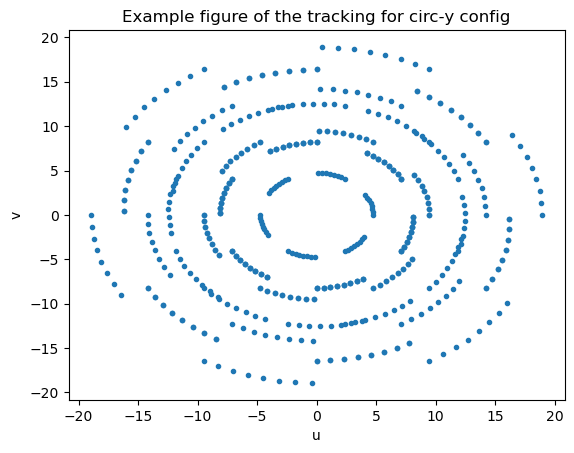

In [13]:
#Standard array examples:

circle_array  = antenna_utils.circular_antenna_arr(n_antenna=n_antenna, r=radius_antenna_grid)
Y_array       = antenna_utils.y_antenna_arr(n_antenna=n_antenna, r=radius_antenna_grid)  # n is per arm
uniform_array = antenna_utils.uni_antenna_array(n_antenna_E=n_antenna_E, n_antenna_N=n_antenna_N, E_lim=radius_antenna_grid, N_lim=radius_antenna_grid, U_lim=0.0)
random_array  = antenna_utils.random_antenna_arr(n_antenna=n_antenna, E_lim=radius_antenna_grid, N_lim=radius_antenna_grid)
circ_y_array  = antenna_utils.combine_antenna_arr(antenna_utils.circular_antenna_arr(n_antenna=n_antenna-3, r=radius_antenna_grid),
                                                  antenna_utils.y_antenna_arr(n_antenna=1, r=1))

# Baselines
b_circ    = antenna_utils.get_baselines(circle_array)
b_Y       = antenna_utils.get_baselines(Y_array)
b_uniform = antenna_utils.get_baselines(uniform_array)
b_random  = antenna_utils.get_baselines(random_array)
b_circ_y  = antenna_utils.get_baselines(circ_y_array)

max_b_circ, max_b_circ_indices = compute_max_baseline(circle_array)
max_b_Y, max_b_Y_indices = compute_max_baseline(Y_array)
max_b_uniform, max_b_uniform_indices = compute_max_baseline(uniform_array)
max_b_random, max_b_random_indices = compute_max_baseline(random_array)
max_b_circ_y, max_b_circ_y_indices = compute_max_baseline(circ_y_array)

print('Max baseline for circular array:', max_b_circ)
print('Max baseline for Y array:', max_b_Y)
print('Max baseline for uniform array:', max_b_uniform)
print('Max baseline for random array:', max_b_random)
print('Max baseline for circular-Y array:', max_b_circ_y)

#tracking
track_time = 2.0 #h
n_times=8 #8 measurements in 2h

uv_circ    = antenna_utils.uv_track_multiband(b_circ, lat=lat, dec=dec, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_Y       = antenna_utils.uv_track_multiband(b_Y, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_uniform = antenna_utils.uv_track_multiband(b_uniform, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_random  = antenna_utils.uv_track_multiband(b_random, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_circ_y  = antenna_utils.uv_track_multiband(b_circ_y, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)

#example figure of the tracking for circ-y config:
plt.figure()
plt.plot(uv_circ_y[0][:,0], uv_circ_y[0][:,1],'.')
plt.title('Example figure of the tracking for circ-y config')
plt.xlabel('u')
plt.ylabel('v')
plt.show()


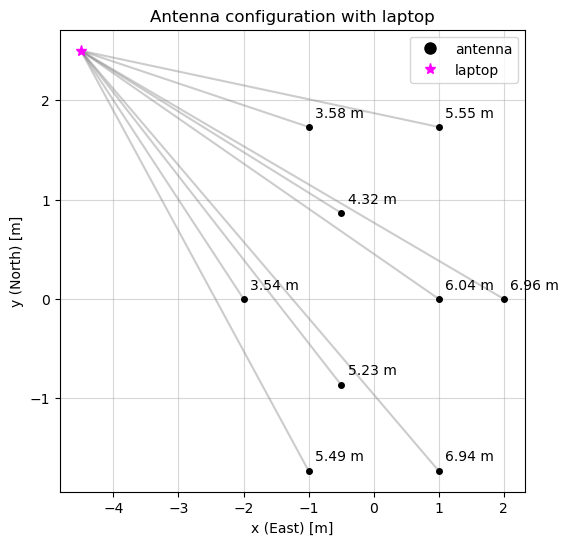

In [14]:
# Calculating laptop distance

laptop_pos = [-4.5, 2.5, 0] #relative to the (0,0,0) of the array

plot_laptop_dist(circ_y_array, laptop_pos=laptop_pos, max_dist=10., offset=.1, savefig=False)


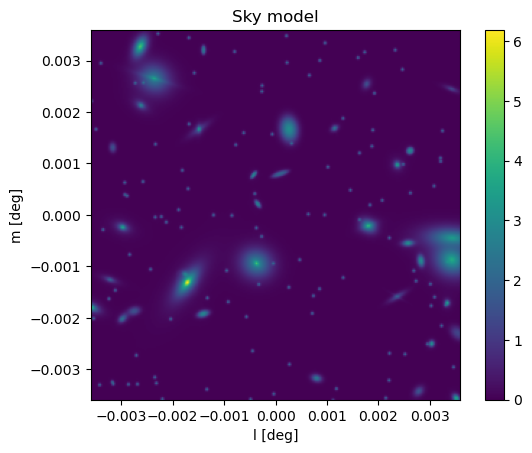

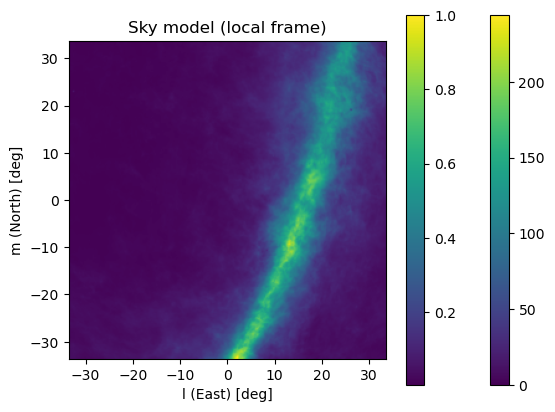

In [27]:
# Some test images (path to image is different for you, as always :))
# galsim_sky.npy and double_wide.png can be downloaded from the argosim github page.
# the hydrogen map (HI4PI_MOM0_GAL_1_1024.fits) comes from https://cade.irap.omp.eu/doku.php?id=hi4pi, on this page download the moment-0 map under Maps in Galactic Coordinates 

#Galsim image
dataset = np.load('galsim_sky.npy', allow_pickle=True)[()]
sky = dataset['image']
fov_size_img = np.sqrt(dataset['field_area_arcmin2'])/60.  # in degrees
plot_utils.plot_sky(sky, (fov_size_img, fov_size_img), title='Sky model')

#Double gaussian source
data_double_gauss_path = 'double_wide.png'
double_gauss_png = Image.open(data_double_gauss_path)
sky_double_gauss = np.array(double_gauss_png)
plot_utils.plot_sky(sky_double_gauss, (fov_size_img, fov_size_img), title='Double Gaussian Source') # FOV is arbitrary, we can decide the scale ourselves

# Leiden, and the time you used for the zenith pointing
location = EarthLocation.from_geodetic(lon=4.49*u.deg, lat=52.16*u.deg, height=0*u.m)
obstime  = Time('2026-11-20 15:00:00')

hi_map = hp.read_map('HI4PI_MOM0_GAL_1_1024.fits', field=0)

n_pix   = 256
FOV_sky = 67.2                                   # deg, full width (256 * 15.75' / 60)

# Local grid around the zenith: l = East, m = North (row 0 = south)
x = np.linspace(-FOV_sky/2, FOV_sky/2, n_pix)
L, M = np.meshgrid(x, x)
l, m = np.radians(L), np.radians(M)

alt = np.arcsin(np.sqrt(1 - l**2 - m**2))
az  = np.arctan2(l, m)                           # azimuth from north, towards east

altaz = SkyCoord(az=az.ravel()*u.rad, alt=alt.ravel()*u.rad,
                 frame=AltAz(obstime=obstime, location=location))
gal = altaz.transform_to(Galactic())

sky_MW = hp.get_interp_val(hi_map, gal.l.deg, gal.b.deg, lonlat=True).reshape(n_pix, n_pix)
sky_MW = sky_MW / sky_MW.max()                   # float, 0..1

plt.imshow(sky_MW, origin='lower', extent=[-FOV_sky/2, FOV_sky/2]*2)
plt.xlabel('l (East) [deg]'); plt.ylabel('m (North) [deg]')
plt.title('Sky model (local frame)'); plt.colorbar(); plt.show()


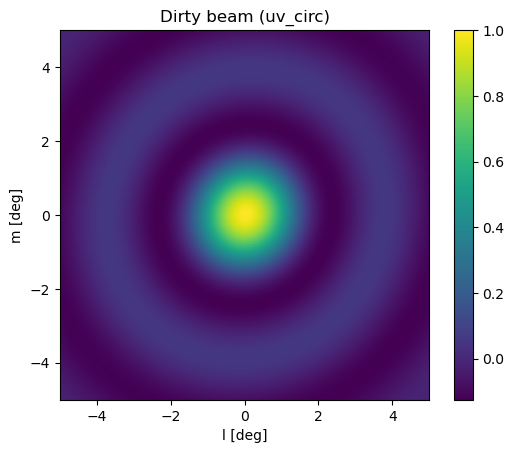

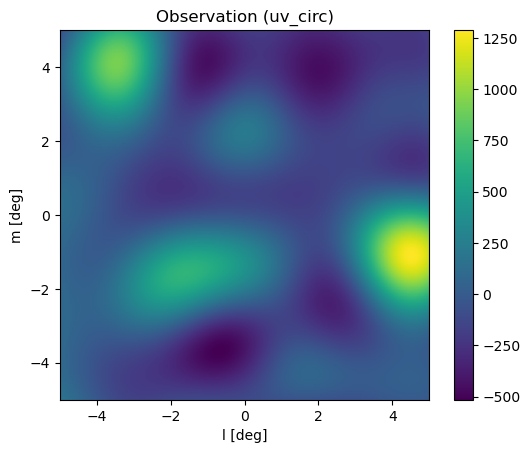

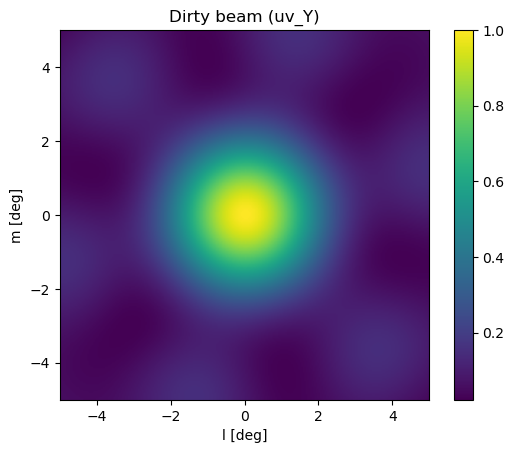

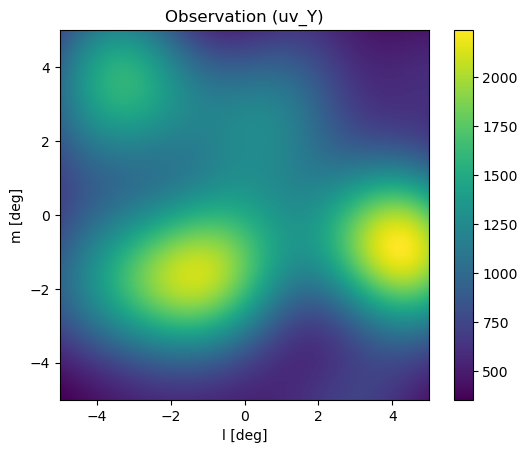

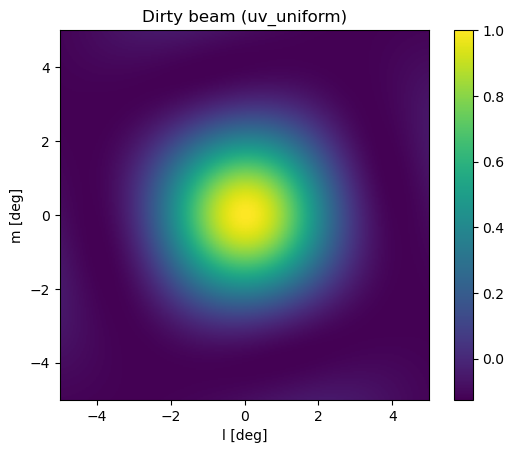

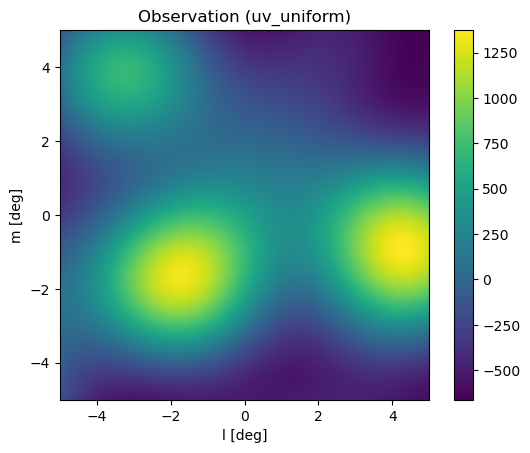

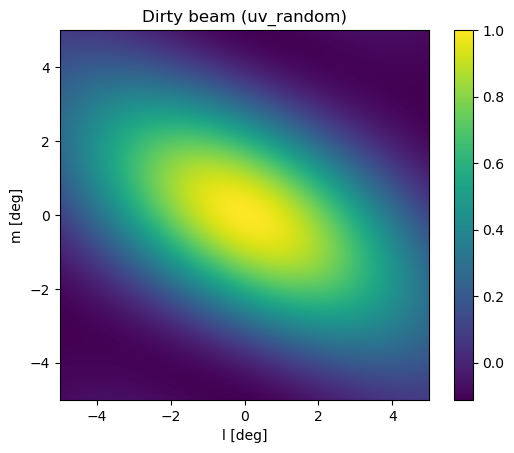

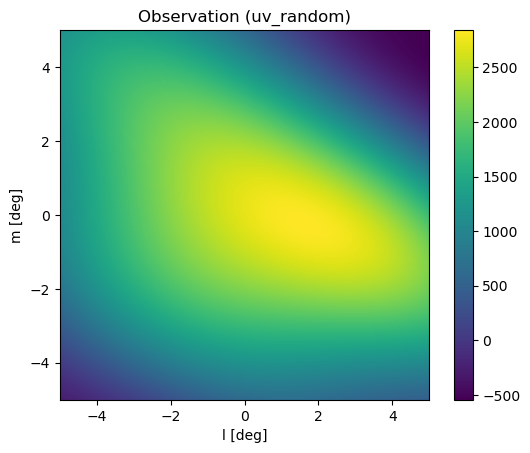

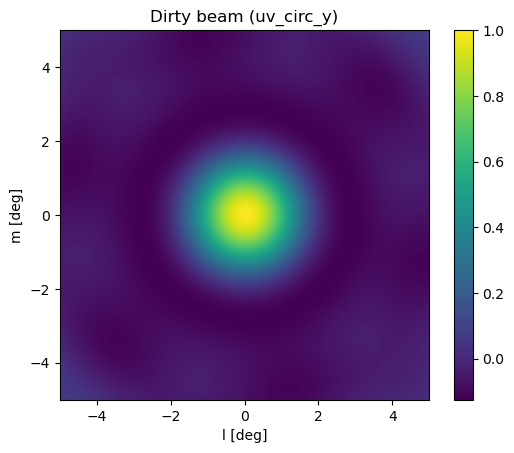

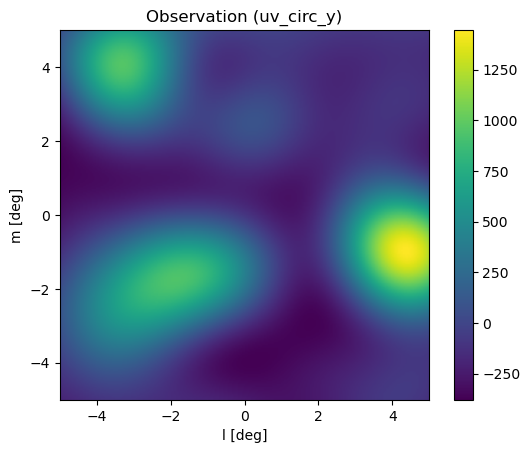

In [29]:
# Performing observations using our array configurations and airy beam:
# Testing what each array layout 'sees' of the sky model from the argosim package

wavelength = (constants.c / frequency).to(u.m)
r_to_first_null = 1.22*wavelength/(diam_ant*u.m) *180/np.pi #82 deg

LAB_new = AiryBeam(r_to_first_null=r_to_first_null.value, n_pix=npix, fov_deg=10) 

obs_Y, dirty_beam_Y = observation(uv_Y, LAB_new.fov_deg, LAB_new, [frequency])
obs_circ, dirty_beam_circ = observation(uv_circ, LAB_new.fov_deg, LAB_new, [frequency])
obs_uniform, dirty_beam_uniform = observation(uv_uniform, LAB_new.fov_deg, LAB_new, [frequency])
obs_random, dirty_beam_random = observation(uv_random, LAB_new.fov_deg, LAB_new, [frequency])
obs_circ_y, dirty_beam_circ_y = observation(uv_circ_y, LAB_new.fov_deg, LAB_new, [frequency])

#Plotting dirty beam and observation for each array for galsim image
uv_list     = [uv_circ, uv_Y, uv_uniform, uv_random, uv_circ_y]
uv_list_str = ["uv_circ", "uv_Y", "uv_uniform", "uv_random", "uv_circ_y"]

for i in range(len(uv_list)):
    obs, dirty_beam = imaging_utils.simulate_dirty_observation(sky, uv_list[i], LAB_new.fov_deg, 
                                                           multi_band=True,
                                                           beam=LAB_new, 
                                                           freqs=[frequency])
    plot_utils.plot_sky(dirty_beam[0], (LAB_new.fov_deg, LAB_new.fov_deg), title=f'Dirty beam ({uv_list_str[i]})')
    plot_utils.plot_sky(obs[0],(LAB_new.fov_deg, LAB_new.fov_deg), title=f'Observation ({uv_list_str[i]})') 
    

## ARRAY OPTIMISATION - Y

Here we make and run our array optimisation function, starting from a Y-shaped array.


In [ ]:
#constants needed in the array optimisation

plt.rcParams['figure.dpi'] = 100
# wavelength, frequency: defined before

#FOV single antenna
FOV = wavelength/(diam_ant*u.m) * 180/np.pi
print('The field of view for a single antenna is:', FOV, 'degrees')

N_ANT = 9 #nr of antennas
R_MAX = 0.5 #half-extent of the site in m
SITE_LIM = R_MAX #max radius from centroid in m
D_MIN = 0.2 #min antenna spacing #m

#config param
npx = 100
bw = 0.7e9
n_freqs = 1
n_times=20
track_h = 0.5 #OBSERVATION TIME
t_0 = 1.0
kernel_W = 1

#constraints
constraints = [
    aou.Constraint('spacing',  lambda a: aou.spacing_penalty(a, D_MIN), weight=10),
    aou.Constraint('radius',   lambda a: aou.radius_penalty(a,  R_MAX), weight=10),
    aou.Constraint('centroid', aou.centroid_penalty,                    weight=10),]

#optimisation
n_steps = 2500


The field of view for a single antenna is: 67.20204449629497 degrees


In [31]:
# Definitions, functions for optimization

def log_spaced_indexes(n_steps, n_snapshots, min_spacing=15):
    """Generate log-spaced indexes with a minimum spacing constraint.
    
    n_steps = total number of steps in the optimization
    n_snapshots = number of snapshots to generate
    min_spacing = minimum spacing between indexes
    """
    # Generate more than needed to ensure we can filter down to n_snapshots
    candidate_indexes = np.unique(np.round(np.logspace(0, np.log10(n_steps), n_snapshots)).astype(int))
    min_spacing_break = np.argmin((candidate_indexes[1:] - candidate_indexes[:-1] - 15)**2)
    linear_indexes = np.arange(candidate_indexes[min_spacing_break], n_steps, min_spacing)
    full_indexes = np.unique(np.concatenate((candidate_indexes[:min_spacing_break], linear_indexes)))
    return full_indexes

#Function to convert antenna positions to UV coverage:
def antenna_to_uv(antenna, config):

    """Convert antenna positions to UV coverage using the argosim package.
    
    antenna : array of antenna positions
    config : configuration object containing parameters like latitude, declination, track time, etc."""

    b_enu = aat.get_baselines(antenna)
    
    track, _ = aat.uv_track_multiband(
        b_ENU=b_enu,
        lat=config.lat,
        dec=config.dec,
        track_time=config.track_h,
        t_0=config.t_0,
        n_times=config.n_times,
        f=config.freq,
        df=config.bw,
        n_freqs=config.n_freqs,
        multi_band=False,)

    return track, b_enu


# change the optimisation function from what is included in argosim originally; 
# consists of two parts, uv-uniformity and baseline-uniformity, will be applied in target_loss_fn
# furthermore, forward_fn will be changed from antenna_to_beam to antenna_to_uv
# We want to specify the uniformity by one single number
# We minimize this in the loss function
def calculate_uniformity(uv_samples, uv_radius, n_grid=20, sigma=None):

    """Function to calculate the uniformity of the uv coverage.
    
    uv_samples : array of uv coordinates
    uv_radius : radius of the uv coverage
    n_grid : number of grid cells in each direction
    sigma : standard deviation for Gaussian smoothing
    """

    #u and v coordinates for all baselines, basically slicing out W
    uv = uv_samples[:, :2]  #shape uv = (1440,3), 1440 = N(N-1)(n_times) = 9x8x20 ,3 = (x,y,x)

    #defining the grid spacing, diameter is divided into 20 parts in each direction
    grid_spacing = 2 * uv_radius / n_grid

    #define sigma for the gaussian smoothing, this way a peak contributes about 13.8% to neighbouring cells, 
    #we smooth because Adam cannot handle delta peaks
    if sigma is None:
        sigma = grid_spacing / 2

    #define uv grid, between centres of first and last cells, 
    grid = jnp.linspace(-uv_radius + grid_spacing / 2, uv_radius - grid_spacing / 2, n_grid)

    #making it 2d
    U, V = jnp.meshgrid(grid, grid)

    #this has shape 400,2, the u and v for every grid point, to which we will compare the actual uv coverage
    grid_points = jnp.stack([U.ravel(), V.ravel()], axis=1)

    #only include cells inside the circular UV region
    mask = jnp.sum(grid_points**2, axis=1) <= uv_radius**2

    #calculate distances from every UV sample to every grid cell, needed for the gaussian smoothing
    #we now know how far every UV sample is from every grid-cell centre
    distances_squared = jnp.sum((uv[:, None, :] - grid_points[None, :, :])**2, axis=2    )

    #gaussian smoothing
    weights = jnp.exp(-distances_squared / (2 * sigma**2))

    #exclude cells outside the circular region
    weights = weights * mask[None, :]

    #normalise each sample's contribution, so samples on the circle edge contribute as much
    weights = weights / (jnp.sum(weights, axis=1, keepdims=True) + 1e-12)

    #total sampling density per cell --> determines how much UV contributes for each of the cells
    counts = jnp.sum(weights, axis=0)

    #calculate thee mean density inside the UV region
    n_cells = jnp.sum(mask)
    mean_density = jnp.sum(counts) / n_cells

    # Normalised variance of the sampling density
    variance = jnp.sum(mask * (counts - mean_density)**2) / n_cells

    #divide by mean^2 because that makes it dimensionless, independent of amount of UV samples
    #twice as many samples --> variance 4x as large
    uniformity = variance / (mean_density**2 + 1e-12)

    return uniformity

# Spacing of the baselines
def calculate_baseline_uniformity(antenna, n_bins=20, sigma=None):

    """Function to calculate the uniformity of the baseline lengths.
    
    antenna : array of antenna positions
    n_bins : number of bins for the baseline lengths
    sigma : standard deviation for Gaussian smoothing
    """

    #antenna input is position array
    
    #get all of the baselines, array of distances between antennas in x,y,z
    baselines = aat.get_baselines(antenna)

    #calculate 1-dimensional distances
    lengths = jnp.sqrt(jnp.sum(baselines**2, axis=1))

    #define min and max allowed/wanted baselines
    min_length = D_MIN
    max_length = 2 * R_MAX

    #define the grid in length coords
    bin_spacing = (max_length - min_length) / n_bins

    #smoothing sigma
    if sigma is None:
        sigma = bin_spacing / 2

    #define grid
    bins = jnp.linspace(min_length + bin_spacing / 2,max_length - bin_spacing / 2,n_bins)

    #define distance (squared) of each length to each bin centre, this is needed for the gauss.
    distances_squared = (lengths[:, None] - bins[None, :])**2

    #assign weights
    weights = jnp.exp(-distances_squared / (2 * sigma**2))

    #normalize weights
    weights = weights / (jnp.sum(weights, axis=1, keepdims=True) + 1e-12)

    #count total contribution to each bin
    counts = jnp.sum(weights, axis=0)

    #determine mean contribution
    mean_density = jnp.mean(counts)

    #determine variance
    variance = jnp.mean((counts - mean_density)**2)
    
    uniformity = variance / (mean_density**2 + 1e-12)

    return uniformity


def resolution(Bmax):

    """Function to calculate the resolution of an array based on the maximum baseline length
    
    Bmax : maximum baseline length
    """
    return (wavelength/u.m)/Bmax


# Combine both requirements in a loss function
def combined_loss(antenna):

    """Function to calculate the combined loss function for the array optimization.
    
    antenna : array of antenna positions
    """

    uv = antenna_to_uv(antenna, config)[0]
    uv_loss = calculate_uniformity(uv,uv_radius=UV_RADIUS,n_grid=20)

    baseline_loss = calculate_baseline_uniformity(antenna)

    L = W_UV * uv_loss + W_BASELINE * baseline_loss

    for c in constraints:
        L = L + c.weight * c.fn(antenna)

    return L

    

Antennas : (9, 3)   baselines: 72
beam shape : (100, 100)   peak: 0.9999999999520574


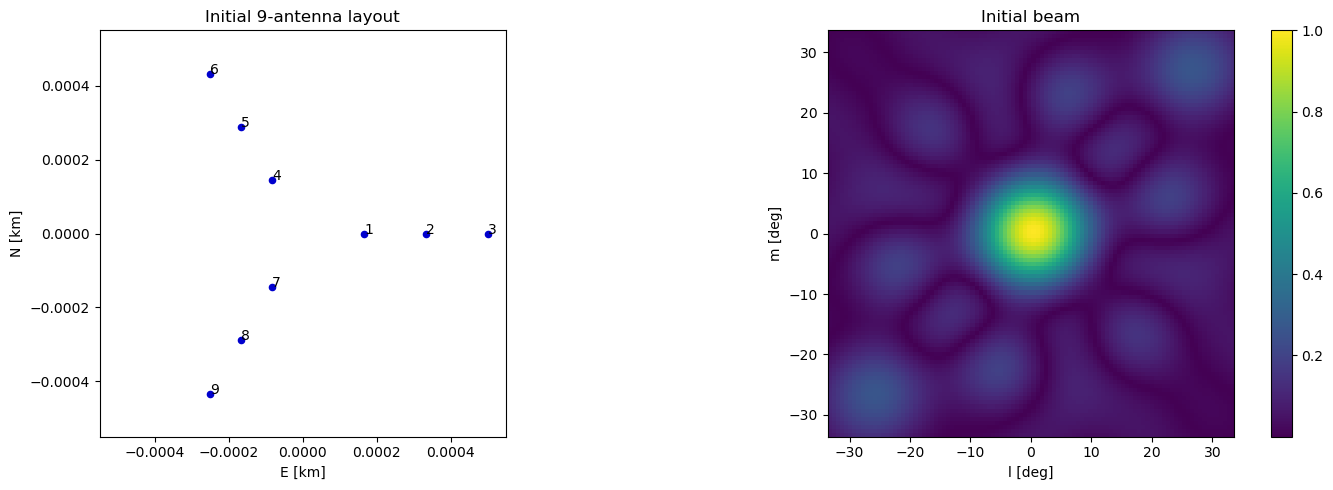

In [32]:
#Setting up the initial antenna configuration and beam to input into the optimisation function

schedule = aou.exp_decay_schedule(init_lr=0.05, end_lr=0.005, transition_steps=500, decay_rate=0.5)
optimizer = aou.make_optimizer('adam', lr=schedule)

config = aou.ObservationConfig(
    npx=npx, fov=FOV,          # FOV = lambda / D_max, converted to degrees
    lat=lat, dec=lat,          #lat is the latitude of the array, dec is the declination of the source (aka milky way)
    freq=frequency/u.Hz, bw=bw, n_freqs=n_freqs, n_times=n_times,
    track_h=track_h, t_0=t_0, kernel_W=kernel_W)

#Initial antenna layout:
antenna_init = jnp.asarray(aat.y_antenna_arr(n_antenna=N_ANT//3, r=SITE_LIM,))

# Centre the array on its mean position
antenna_init = antenna_init - jnp.mean(antenna_init, axis=0, keepdims=True)
print('Antennas :', antenna_init.shape, '  baselines:', N_ANT*(N_ANT-1))

forward_fn = lambda antenna: aou.antenna_to_beam(antenna, config)      #Is this antenna beam correct/does that matter?
beam0 = forward_fn(antenna_init)
print('beam shape :', beam0.shape, '  peak:', float(beam0.max()))

#2D angular distance map, needed for the airy beam
npx = config.npx
pixel_scale = (config.fov*u.deg).to(u.rad).value / npx
x = (np.arange(npx) - npx // 2) * pixel_scale
y = (np.arange(npx) - npx // 2) * pixel_scale
xx, yy = np.meshgrid(x, y)
angular_distance = np.sqrt(xx**2 + yy**2) * u.rad

airy_fn = airy_beam_fn(1.22 * (wavelength/u.m) / diam_ant *180/np.pi *u.deg)
primary_beam = airy_fn(angular_distance)
combined_beam = np.array(beam0) * primary_beam

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
apu.plot_antenna_arr(antenna_init, ax=axes[0], fig=fig, title=f'Initial {N_ANT}-antenna layout')
apu.plot_sky(np.array(combined_beam),       (config.fov, config.fov), axes[1], fig, title='Initial beam')
plt.tight_layout(); plt.show()


In [33]:
# Running the optimization

UV_RADIUS = 2 * R_MAX / wavelength/u.m

uniformity_loss = calculate_uniformity(antenna_to_uv(antenna_init,config)[0],UV_RADIUS)
baseline_loss = calculate_baseline_uniformity(antenna_init)

print("Initial uniformity loss:", float(uniformity_loss))
print("Initial baseline uniformity loss:", float(baseline_loss))

#apply weighting for both constraints
W_UV = 1.0
W_BASELINE = 1.0

print("Combined loss:", float(combined_loss(antenna_init)))


Initial uniformity loss: 2.131550355182404
Initial baseline uniformity loss: 0.9864745402420575
Combined loss: 4.784691562091128


In [ ]:
# Running the optimization using our new combined loss function

snapshot_steps = log_spaced_indexes(n_steps, n_snapshots=100, min_spacing=15)

result = aou.optimise_array(
    antenna_init=antenna_init,
    loss_fn=combined_loss,
    optimizer=optimizer,
    n_steps=n_steps,
    snapshot_steps=snapshot_steps,
    freeze_u=True,
    verbose_every=50,
)

antenna       = result['antenna']
loss_history  = result['loss_history']
snap_ant      = result['snapshots_antenna']
snap_loss     = result['snapshots_loss']
snapshot_step = result['snapshots_step']

print(f'\nFinal loss = {loss_history[-1]:.5f}   (initial = {loss_history[0]:.5f})')
print(f'Snapshots : {len(snap_ant)}  (steps: {snapshot_step[:6].tolist()} ... {snapshot_step[-3:].tolist()})')


step    0   loss = 4.78469
step   50   loss = 1.24052
step  100   loss = 1.14877
step  150   loss = 1.14841
step  200   loss = 1.14841
step  250   loss = 1.14841
step  300   loss = 1.14841
step  350   loss = 1.14841
step  400   loss = 1.14841
step  450   loss = 1.14841
step  500   loss = 1.14841
step  550   loss = 1.14841
step  600   loss = 1.14841
step  650   loss = 1.14841
step  700   loss = 1.14841
step  750   loss = 1.14841
step  800   loss = 1.14841
step  850   loss = 1.14841
step  900   loss = 1.14841
step  950   loss = 1.14841
step 1000   loss = 1.14841
step 1050   loss = 1.14841
step 1100   loss = 1.14841
step 1150   loss = 1.14841
step 1200   loss = 1.14841
step 1250   loss = 1.14841
step 1300   loss = 1.14841
step 1350   loss = 1.14841
step 1400   loss = 1.14841
step 1450   loss = 1.14841
step 1500   loss = 1.14841
step 1550   loss = 1.14841
step 1600   loss = 1.14841
step 1650   loss = 1.14841
step 1700   loss = 1.14841
step 1750   loss = 1.14841
step 1800   loss = 1.14841
s

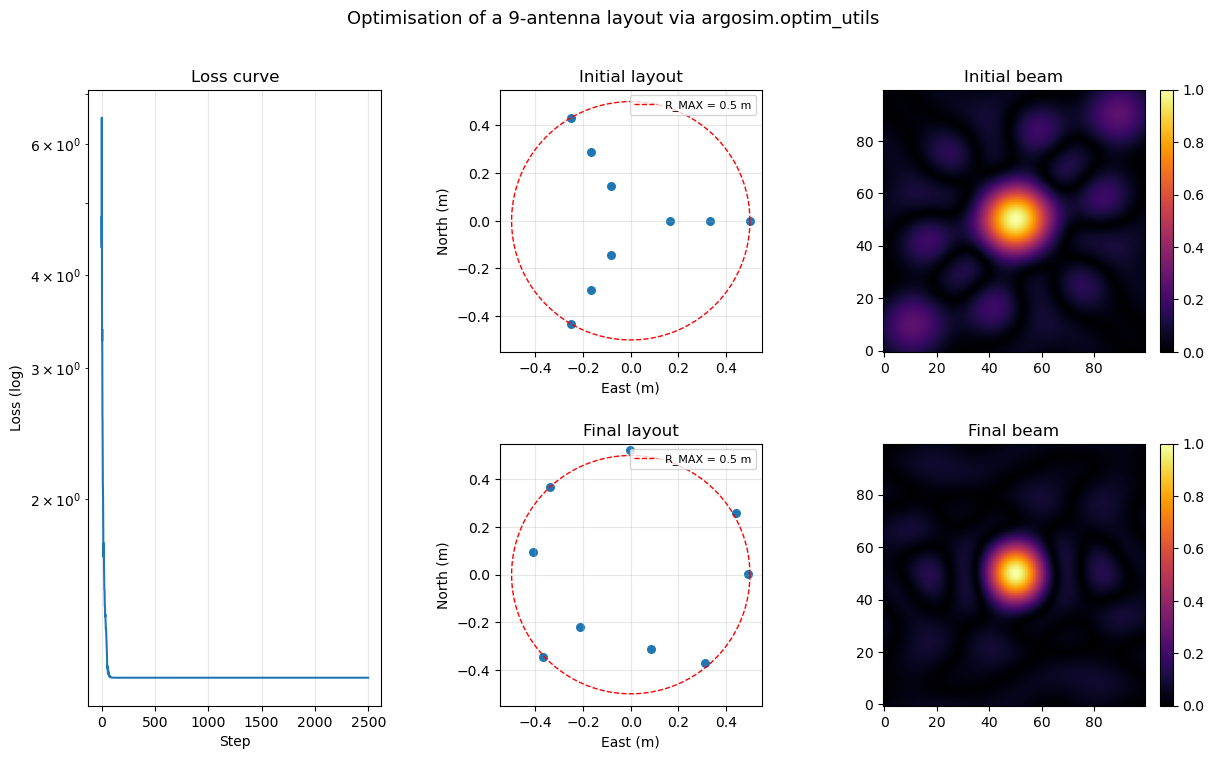

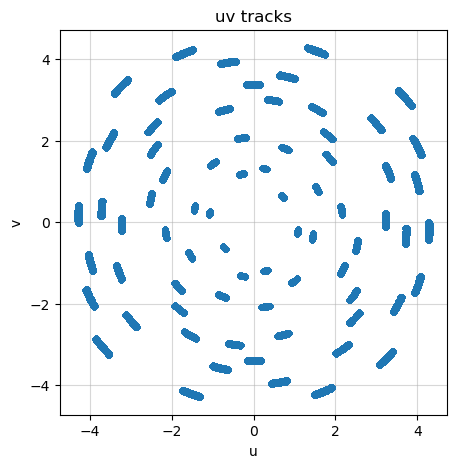

In [37]:
#Plotting the results of our optimisation as well as the UV-tracks of the final layout

ant_final = np.array(antenna)
ant_init = np.array(antenna_init)
beam_final = np.array(forward_fn(antenna)) * primary_beam
beam_initial = np.array(forward_fn(antenna_init)) * primary_beam


fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35)

ax_loss = fig.add_subplot(gs[:, 0])
ax_loss.semilogy(loss_history)
ax_loss.set_xlabel('Step')
ax_loss.set_ylabel('Loss (log)')
ax_loss.set_title('Loss curve')
ax_loss.grid(True, alpha=0.3)

theta = np.linspace(0, 2*np.pi, 200)

for row, (arr, label) in enumerate([(ant_init, 'Initial'), (ant_final, 'Final')]):
    ax = fig.add_subplot(gs[row, 1])
    ax.scatter(arr[:, 0], arr[:, 1], s=30)
    cx, cy = arr[:, 0].mean(), arr[:, 1].mean()
    ax.plot(cx + R_MAX*np.cos(theta), cy + R_MAX*np.sin(theta),
            'r--', lw=1, label=f'R_MAX = {R_MAX:.1f} m')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_ylim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_title(f'{label} layout')

vmax = max(beam_initial.max(), beam_final.max())

for row, (img, label) in enumerate([(beam_initial, 'Initial beam'), (beam_final, 'Final beam')]):
    ax = fig.add_subplot(gs[row, 2])
    im = ax.imshow(img, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_title(label)

plt.suptitle(f'Optimisation of a {N_ANT}-antenna layout via argosim.optim_utils',
             fontsize=13)
plt.show()

b_optim = aat.get_baselines(ant_final)
uv_optim = uv_tracks(b_optim, track_time=track_h, n_times=20,
                     lat=lat_deg, dec=lat_deg, f=frequency/u.Hz)
plot_uv(uv_optim)


Minimum baseline: 0.20004309159007433 m
Maximum baseline: 1.0126115897378307 m


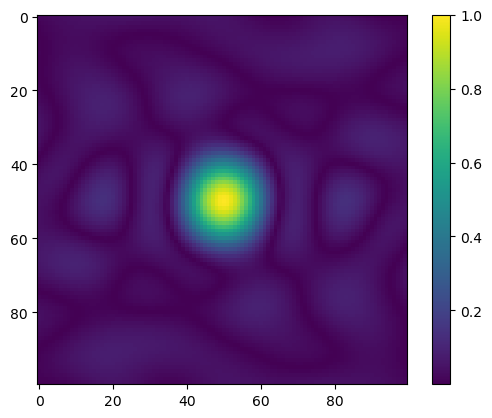

The max of the psf is at pixel 50 50 with value 0.9999999999472191
The 2nd max of the psf is at pixel 51 50 with value 0.9926935914155521
The PSF has a unique maximum


In [41]:
# Checking the point spread function (psf) and baseline lengths of the final array configuration
baseline_lengths = np.linalg.norm(b_optim, axis=1)

print("Minimum baseline:", baseline_lengths.min(), "m")
print("Maximum baseline:", baseline_lengths.max(), "m")

#beam psf findings
plt.figure()
plt.imshow(beam_final)
plt.colorbar()
plt.show()

beam_final_2 = beam_final.copy()
row_max, col_max = np.unravel_index(beam_final_2.argmax(), beam_final_2.shape)

print('The max of the psf is at pixel',row_max,col_max, 'with value', beam_final_2[row_max,col_max])

beam_final_masked = beam_final_2.copy()
beam_final_masked[row_max,col_max] = 0.0
row_masked, col_masked = np.unravel_index(beam_final_masked.argmax(), beam_final_masked.shape)

print('The 2nd max of the psf is at pixel',row_masked,col_masked, 'with value', beam_final_masked[row_masked,col_masked])

if beam_final_masked[row_masked,col_masked] <  beam_final_2[row_max,col_max]:
    print('The PSF has a unique maximum')
else: 
    pass

In [42]:
# Calculating the resolution of the interferometer and sidelobes of the array beam

print('The resolution of the interferometer is',resolution(baseline_lengths.max())*u.deg)

#mask the main lobe
beam_final_masked_center = beam_final.copy()
radius = 14  # chosen based on the width of the main lobe

Y, X = np.ogrid[:beam_final.shape[0], :beam_final.shape[1]]
main_lobe_mask = (Y - row_max)**2 + (X - col_max)**2 <= radius**2
beam_final_masked_center[main_lobe_mask] = 0.0

#find maximum sidelobe
max_sidelobe = np.max(np.abs(beam_final_masked_center))

#calculate relative sidelobe level
max_sll = max_sidelobe / abs(beam_final[row_max, col_max])

# Convert to dB
max_sll_dB = 20 * np.log10(max_sll)

print('Maximum sidelobe level:', max_sll)
print('Maximum sidelobe level:', max_sll_dB, 'dB')


#select all pixels outside the main lobe
sidelobes = beam_final[~main_lobe_mask]

#calculate RMS sidelobe level
rms_sidelobe = np.sqrt(np.mean(sidelobes**2))

#normalise relative to central peak
rms_sll = rms_sidelobe / abs(beam_final[row_max, col_max])
rms_sll_dB = 20 * np.log10(rms_sll)

print('RMS sidelobe level:', rms_sll)
print('RMS sidelobe level:', rms_sll_dB, 'dB')

The resolution of the interferometer is 0.2084920333080869 deg
Maximum sidelobe level: 0.18138784057656765
Maximum sidelobe level: -14.827836588902745 dB
RMS sidelobe level: 0.04784642618402675
RMS sidelobe level: -26.403009912819254 dB


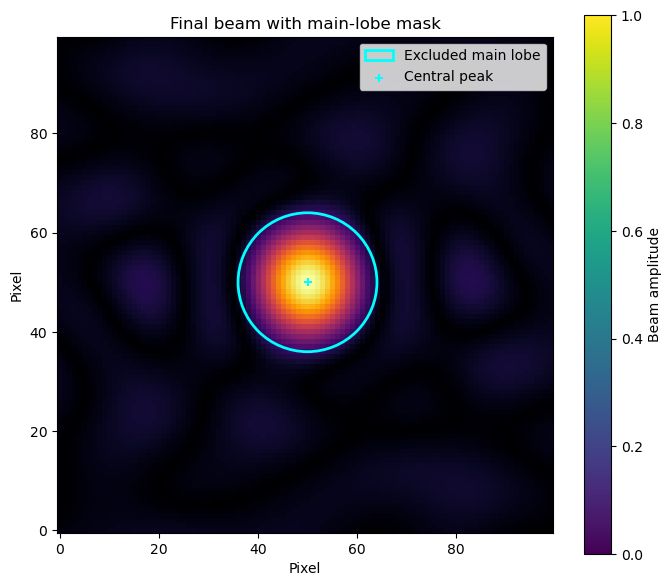

In [43]:
# Plotting the final beam with main-lobe mask

plt.figure(figsize=(8, 7))
plt.imshow(beam_final, origin='lower', cmap='inferno')

# Plot the main-lobe mask boundary
circle = plt.Circle(
    (col_max, row_max),
    radius,
    color='cyan',
    fill=False,
    linewidth=2,
    label='Excluded main lobe')

plt.gca().add_patch(circle)
plt.scatter(col_max, row_max, color='cyan', marker='+', label='Central peak')
plt.colorbar(label='Beam amplitude')
plt.legend()
plt.title('Final beam with main-lobe mask')
plt.xlabel('Pixel')
plt.ylabel('Pixel')
plt.show()

uv samples: (1440, 3)


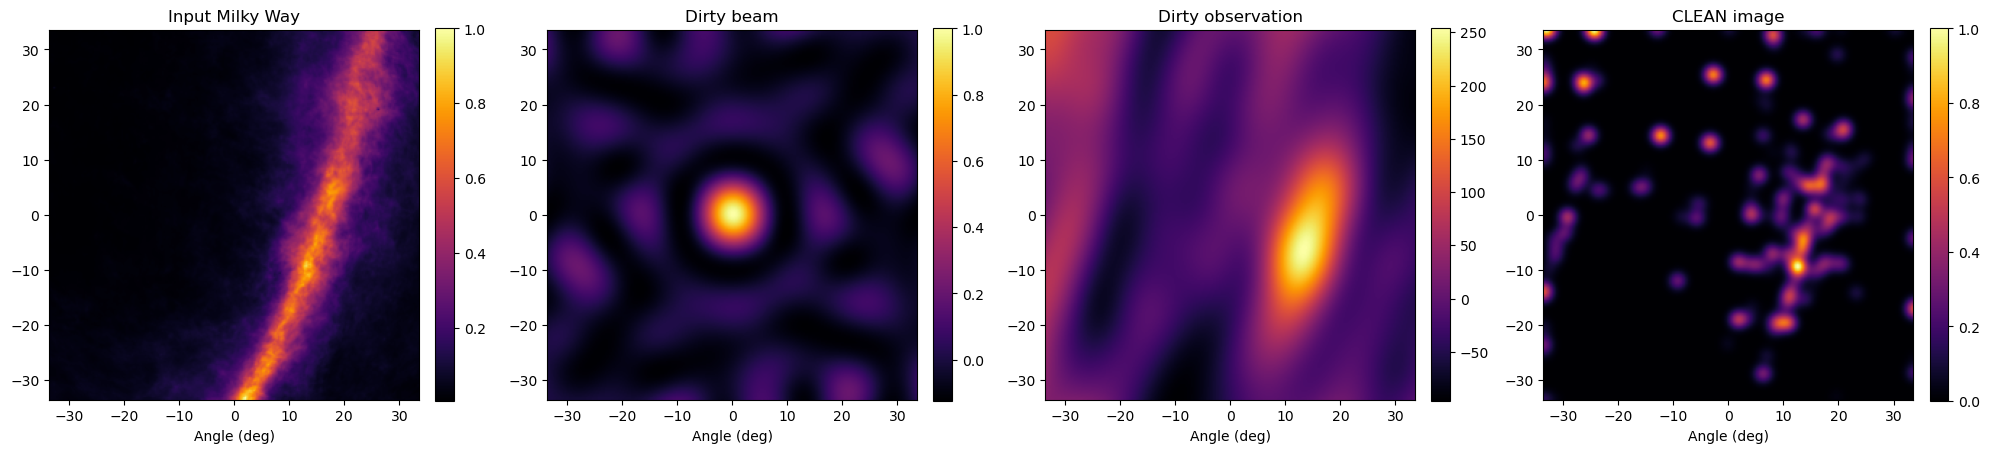

In [44]:
# Create overview image showing MW input, array beam, dirty image and CLEAN image (for only 100 iterations of CLEAN)

b_final = aat.get_baselines(np.array(antenna))
uv_obs = antenna_utils.uv_track_multiband(
    b_final, lat=lat, dec=lat,
    track_time=track_h, t_0=t_0, n_times=n_times, f=frequency)
print("uv samples:", uv_obs[0].shape)

# Define beam
airy_beam = AiryBeam(r_to_first_null=r_to_first_null.value,
                     n_pix=n_pix, fov_deg=FOV_sky/2)

# Generate dirty image
obs, dirty_beam = imaging_utils.simulate_dirty_observation(
    sky_MW, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])

# Generate CLEAN image
I_clean, sky_model = clean_hogbom(
    obs[0],
    dirty_beam[0],
    gamma=0.1,
    max_iter=1000,
    threshold=1e-3,
    clean_beam_size_px=10,
    res=False)

I_clean /= np.max(I_clean)


# Plot all four images next to each other
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

images = [sky_MW, dirty_beam[0], obs[0], I_clean]

titles = ["Input Milky Way", "Dirty beam", 
          "Dirty observation", "CLEAN image"]

for i in range(4):
    im = ax[i].imshow(
        images[i],
        origin='lower',
        extent=[-FOV_sky/2, FOV_sky/2,
                -FOV_sky/2, FOV_sky/2],
        cmap='inferno')

    ax[i].set_title(titles[i])
    ax[i].set_xlabel("Angle (deg)")
    ax[i].set_aspect('equal')

    plt.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04)

plt.tight_layout()
# plt.savefig('9_ant_0.4m_Yconfig_result.pdf')
plt.show()


## Array layout figure

Here we generate a figure to include in the Overleaf so other groups can easily understand the final array configuration and have coordinates of the antenna positions.

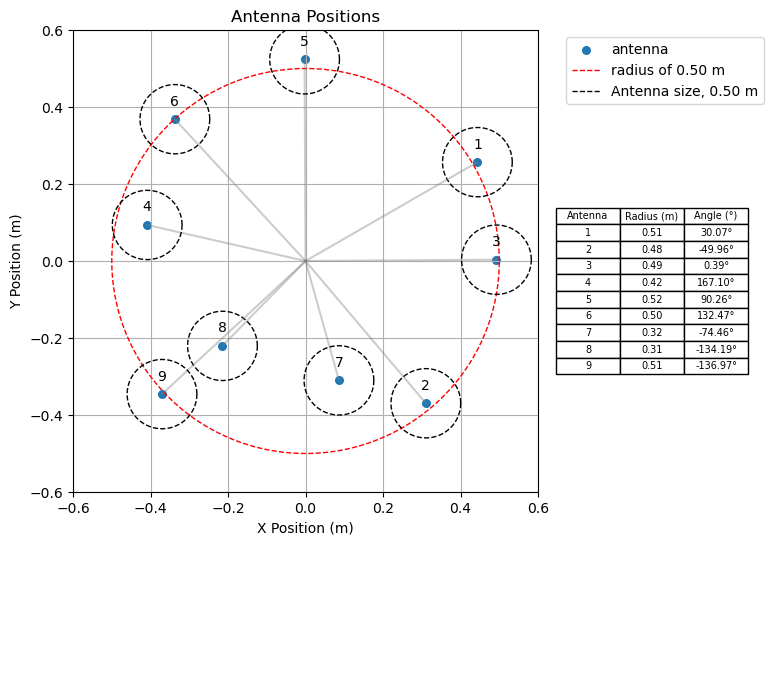

In [45]:

# final antenna positions as radii and angles from the centre of the array
radii = np.sqrt(ant_final[:, 0]**2 + ant_final[:, 1]**2)
angles = np.arctan2(ant_final[:, 1], ant_final[:, 0])

theta = np.linspace(0, 2*np.pi, 200)

z = []
for i in range(len(ant_final)):
    z.append(str(i+1))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ant_final[:, 0], ant_final[:, 1], s=30, label='antenna')
ax.plot(0 + R_MAX*np.cos(theta), 0 + R_MAX*np.sin(theta), 'r--', lw=1, label=f'radius of {R_MAX:.2f} m')

ax.set_xlabel('X Position (m)')
ax.set_ylabel('Y Position (m)')
ax.set_title('Antenna Positions')

ax.plot(ant_final[0, 0] + 0.09*np.cos(theta), ant_final[0, 1] + 0.09*np.sin(theta), '--', color='black', lw=1, label=f'Antenna size, {R_MAX:.2f} m')
ax.plot([ant_final[0, 0], 0.0], [ant_final[0, 1], 0.0], alpha=.4, color='gray')
ax.annotate(z[0], (ant_final[0, 0], ant_final[0, 1]), textcoords="offset points", xytext=(0,10), ha='center')

for i, txt in enumerate(z[1:]):
    ax.plot([ant_final[i+1, 0], 0.0], [ant_final[i+1, 1], 0.0], alpha=.4, color='gray')
    ax.plot(ant_final[i+1, 0] + 0.09*np.cos(theta), ant_final[i+1, 1] + 0.09*np.sin(theta), '--', color='black', lw=1)
    ax.annotate(txt, (ant_final[i+1, 0], ant_final[i+1, 1]), textcoords="offset points", xytext=(0,10), ha='center')

ax.grid(True)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.6, 0.6)
ax.legend(loc='upper right', bbox_to_anchor=(1.5, 1.0))

cell_text = [[str(i+1), f"{radii[i]:.2f}", f"{np.degrees(angles[i]):.2f}°"] for i in range(len(ant_final))]
table_ax = fig.add_axes([0.93, -0.2, 0.32, 0.8])  # [left, bottom, width, height]
table_ax.axis('off')
table = table_ax.table(cellText=cell_text, colLabels=["Antenna", "Radius (m)", "Angle (°)"], loc='upper center', cellLoc='center')

plt.savefig('antenna_positions_with_table.pdf', bbox_inches='tight')
plt.show()


## Beam

Here we investigate the beam of the final array configuration.

FWHM x: 16.195723583046952 pixels
FWHM y: 17.70851565248768 pixels
FWHM x: 10.883526247807552 degrees
FWHM y: 11.900122518471722 degrees
Position angle: -0.0542491777144188 radians
Major axis peaks: [array([-22.06060606, -13.23636364,  -0.33939394,  13.23636364,
        22.06060606,  32.92121212]), array([0.12763908, 0.08632676, 0.99572167, 0.08632676, 0.12763908,
       0.03684311])]
Minor axis peaks: [array([-20.02424242,   0.33939394,  20.02424242,  32.92121212]), array([0.05872542, 0.99609207, 0.05872542, 0.05122287])]


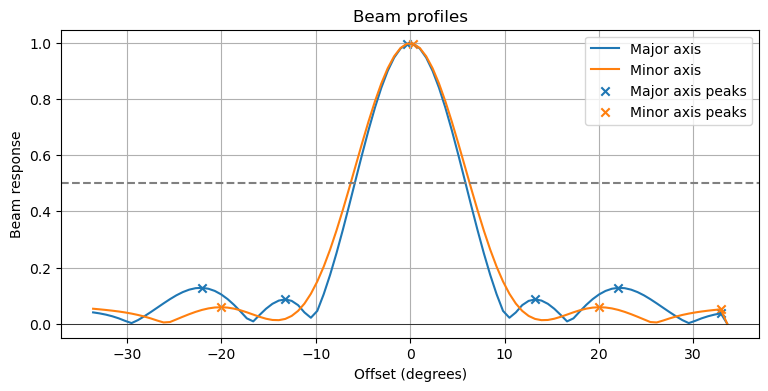

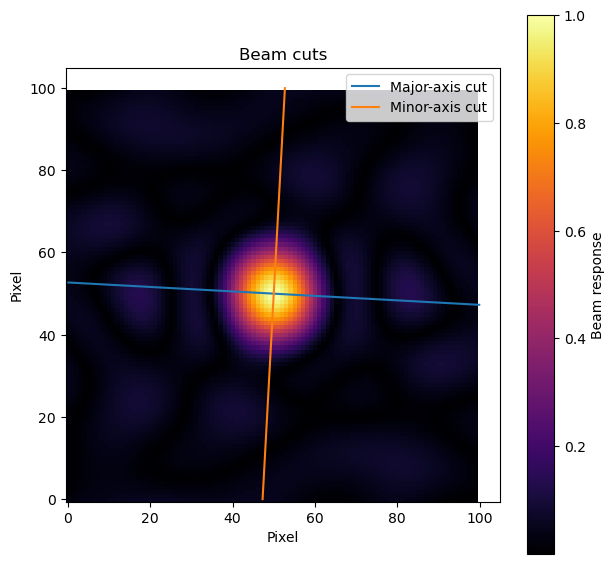

In [46]:

#Fitting a Gaussian to the central beam
centre = beam_final.shape[0] // 2
radius = 20  # pixels; adjust to include central lobe only

beam_centre = beam_final[
    centre-radius:centre+radius+1,
    centre-radius:centre+radius+1
]

y, x = np.indices(beam_centre.shape)

gauss_init = models.Gaussian2D(
    amplitude=np.max(beam_centre),
    x_mean=radius,
    y_mean=radius,
    x_stddev=5,
    y_stddev=5
)

fit = fitting.LevMarLSQFitter()
gauss_fit = fit(gauss_init, x, y, beam_centre)

# Calculating the FWHM
factor = 2 * np.sqrt(2 * np.log(2))

fwhm_x = factor * gauss_fit.x_stddev.value
fwhm_y = factor * gauss_fit.y_stddev.value

pixel_scale = FOV_sky / beam_final.shape[1]

print("FWHM x:", fwhm_x, "pixels")
print("FWHM y:", fwhm_y, "pixels")
print("FWHM x:", fwhm_x * pixel_scale, "degrees")
print("FWHM y:", fwhm_y * pixel_scale, "degrees")
print("Position angle:", gauss_fit.theta.value, "radians")

# Extracting beam response profiles along fitted axes
theta = gauss_fit.theta.value

r = np.linspace(-centre, centre, beam_final.shape[0])

# Major axis
x_major = centre + r * np.cos(theta)
y_major = centre + r * np.sin(theta)

# Minor axis
x_minor = centre - r * np.sin(theta)
y_minor = centre + r * np.cos(theta)

profile_major = map_coordinates(
    beam_final, [y_major, x_major], order=1
)

profile_minor = map_coordinates(
    beam_final, [y_minor, x_minor], order=1
)

offset = r * pixel_scale

#Find the peaks
peaks_major_i, _ = find_peaks(profile_major)
peaks_minor_i, _ = find_peaks(profile_minor)

profile_major_peaks = profile_major[peaks_major_i]
profile_minor_peaks = profile_minor[peaks_minor_i]

peaks_major = [offset[peaks_major_i], profile_major_peaks]
peaks_minor = [offset[peaks_minor_i], profile_minor_peaks]

print("Major axis peaks:", peaks_major)
print("Minor axis peaks:", peaks_minor)

# Plotting the 1D profiles
plt.figure(figsize=(9, 4))

plt.plot(offset, profile_major, label="Major axis")
plt.plot(offset, profile_minor, label="Minor axis")
plt.axhline(np.max(beam_final) / 2, color='grey', linestyle='--')
plt.axhline(0, color='black', linewidth=0.5)
plt.scatter(peaks_major[0], peaks_major[1], color='C0', marker='x', label='Major axis peaks')
plt.scatter(peaks_minor[0], peaks_minor[1], color='C1', marker='x', label='Minor axis peaks')

plt.xlabel("Offset (degrees)")
plt.ylabel("Beam response")
plt.title("Beam profiles")
plt.legend()
plt.grid()
plt.savefig('1d_plot_beam_ellipse.pdf')
plt.show()



# Plotting cuts on the 2D beam
plt.figure(figsize=(7, 7))

plt.imshow(beam_final, origin='lower', cmap='inferno')

plt.plot(x_major, y_major, color='C0', label='Major-axis cut')
plt.plot(x_minor, y_minor, color='C1', label='Minor-axis cut')

plt.xlabel("Pixel")
plt.ylabel("Pixel")
plt.title("Beam cuts")
plt.legend()
plt.colorbar(label="Beam response")
plt.savefig('2d_beam_ellipse_cutouts.pdf')
plt.show()

## Baselines

Here we look at the different baselines of the final array to find the best possible distribution of the antenna among laptops, using the specifications given to us by the data acquisition team.

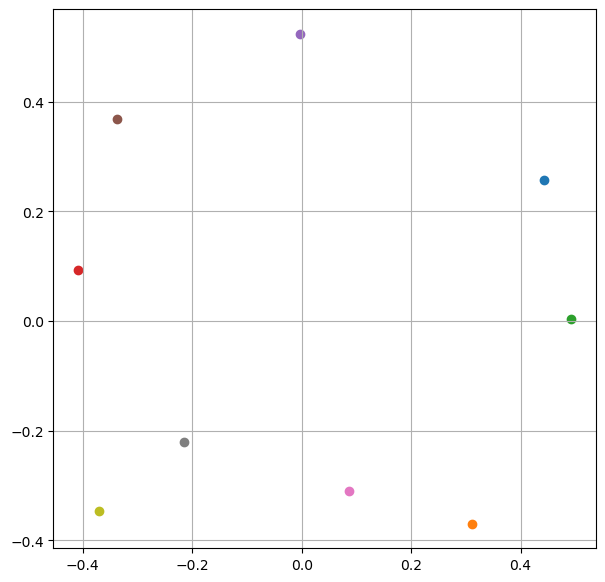

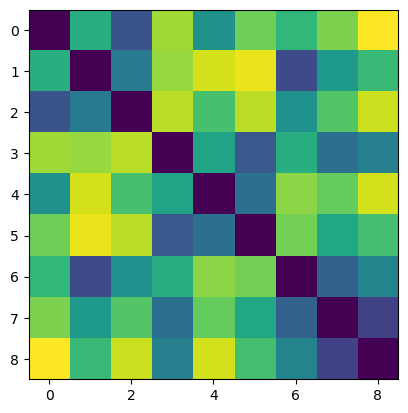

[7 8]
minimal baseline: 0.20004308807400498
[0 8]
max baseline: 1.0126115853515187
11.945713622399404


In [48]:
# Final array position
ant_final = np.array([[1, 0.44351937, 0.25675033],
        [2, 0.31049445, -0.36953188],    
        [3, 0.49270715, 0.00338735],
        [4, -0.40862047, 0.09358719],
        [5, -0.00241969, 0.52380058],
        [6, -0.33720132, 0.36831369],
        [7, 0.08623691, -0.3100637],
        [8, -0.21437422, -0.22048946],
        [9, -0.37034218, -0.34575411]])
R_MAX = 1
antenna_final = ant_final

# Plotting the final antenna positions
fig, ax = plt.subplots(figsize=(7, 7))
for i in range(len(ant_final)):
    ax.scatter(ant_final[i,1], ant_final[i,2])
    ax.annotate(str(ant_final[i,0]), (ant_final[i, 0], ant_final[i, 1]), textcoords="offset points", xytext=(0,10), ha='center')
plt.grid()
plt.show()

# Calculating and plotting the baseline lengths in the final array configuration
x = antenna_final[:, 1]
y = antenna_final[:, 2]
baseline_M = np.zeros((len(antenna_final), len(antenna_final)))
for i in range(len(antenna_final)):
    for j in range(len(antenna_final)):
        baseline_M[i, j] = np.sqrt((x[i] - x[j])**2 + (y[i] - y[j])**2)

plt.imshow(baseline_M)
plt.show()

baseline_M_nodiag = baseline_M + 0.5*np.identity(len(baseline_M))
min1, min2 = np.argwhere(baseline_M_nodiag == np.min(baseline_M_nodiag))
print(min1) # antenna corresponding to the minimum baseline
print('minimal baseline:', baseline_M[min1[0],min1[1]]) # minimum baseline length

max1, max2 = np.argwhere(baseline_M_nodiag == np.max(baseline_M_nodiag))
print(max1) # antenna corresponding to the maximum baseline
print('max baseline:', baseline_M[max1[0],max1[1]]) # maximum baseline length

# Calculating the resolution of the interferometer based on the maximum baseline
resolution = (wavelength/(baseline_M[max1[0],max1[1]]*u.m)) / np.pi *180
print(resolution)

In [49]:

# writing a function to split the 9 antennas into groups of 4, 3, and 2 to ensure the best possible baseline distribution and angular diversity
def split_4_3_2(items):
    """Function to split a list of items into groups of 4, 3, and 2.
    
    items: list of items to split
    """
    items = set(items)
    for a in combinations(sorted(items), 4):
        rest = items - set(a)
        for b in combinations(sorted(rest), 3):
            c = tuple(sorted(rest - set(b)))
            yield a+ b+ c

def normalize(a):
    """Function to normalize an array to the range [0, 1].
    
    a: array to normalize
    """
    return np.abs((a - a.min()) / (a.max() - a.min()))
    
# Applying these functions to the final antenna positions
result = np.array(list(split_4_3_2(range(1, 10))))

group4 = result[:, :4]    # shape (1260, 4)
group3 = result[:, 4:7]   # shape (1260, 3)
group2 = result[:, 7:]    # shape (1260, 2)

total_b_score_l = []
div_angle_l = []
for i in range(len(result)):
    combis = result[i]

    group4 = result[i, :4]    # shape (1260, 4)
    group3 = result[i, 4:7]   # shape (1260, 3)
    group2 = result[i, 7:]    # shape (1260, 2)

    group4_combis = combinations(group4, 2)
    b_4 = 0
    theta_4 = np.array([])
    for j, combi in enumerate(group4_combis):
        k, l = combi
        b = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)
        b_4 += b

        theta = np.arctan2(y[k-1] - y[l-1], x[k-1] - x[l-1])
        theta_4 = np.append(theta_4, theta)

    diversity_4 = 1 - np.abs(np.mean(np.exp(2j * theta_4)))
    
    group3_combis = combinations(group3, 2)
    b_3 = 0
    theta_3 = np.array([])
    for j, combi in enumerate(group3_combis):
        k, l = combi
        b = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)
        b_3 += b

        theta = np.arctan2(y[k-1] - y[l-1], x[k-1] - x[l-1])
        theta_3 = np.append(theta_3, theta)
    
    diversity_3 = 1 - np.abs(np.mean(np.exp(2j * theta_3)))
    
    k, l = group2
    b_2 = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)        

    diversity_angle = np.mean((diversity_4, diversity_3))
    div_angle_l.append(diversity_angle)
    total_b_score = b_4 + b_3 + b_2
    total_b_score_l.append(total_b_score)

total_b_score_l = np.asarray(total_b_score_l)
div_angle_l = np.asarray(div_angle_l)

dees = normalize(total_b_score_l)
www = 0.5
score = dees - www * div_angle_l

min_i = np.argwhere(score == min(score))
best_combinations = result[min_i][0,0]

best_group4, best_group3, best_group2 = best_combinations[:4], best_combinations[4:7], best_combinations[7:]
print(best_group4, best_group3, best_group2)



[1 2 3 7] [4 8 9] [5 6]
